In [27]:
import numpy as np
import cv2
import mediapipe as mp
import os
import matplotlib.pyplot as plt

# Initialize MediaPipe Face Detection
mp_face_detection = mp.solutions.face_detection
mp_drawing = mp.solutions.drawing_utils
mp_drawing_styles = mp.solutions.drawing_styles

BaseOptions = mp.tasks.BaseOptions
FaceLandmarker = mp.tasks.vision.FaceLandmarker
FaceLandmarkerOptions = mp.tasks.vision.FaceLandmarkerOptions
VisionRunningMode = mp.tasks.vision.RunningMode

# Load the Face Landmarker model
# You can download the model from: https://developers.google.com/mediapipe/solutions/vision/face_landmarker#models
# Replace 'face_landmarker.task' with the actual path to your downloaded model file.

options = FaceLandmarkerOptions(
    base_options=BaseOptions(model_asset_path=os.path.relpath('face_landmarker.task')),
    running_mode=VisionRunningMode.LIVE_STREAM, # Use IMAGE for single image processing
    num_faces=1 # Detect up to 1 face
)


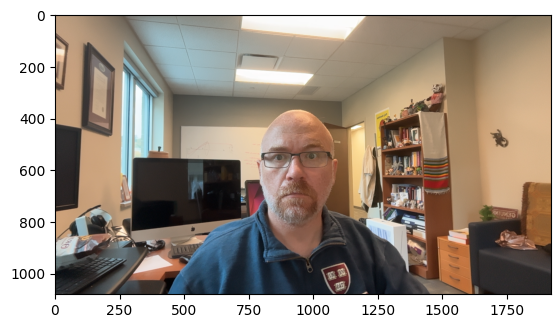

In [28]:
cam = cv2.VideoCapture(0)
_, frame = cam.read()
frame = cv2.flip(frame, 1)

frame_rgb=cv2.cvtColor(frame,cv2.COLOR_BGR2RGB)
plt.imshow(frame_rgb)

I0000 00:00:1762186237.932917 1570745 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M4 Pro
W0000 00:00:1762186237.934092 1571307 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


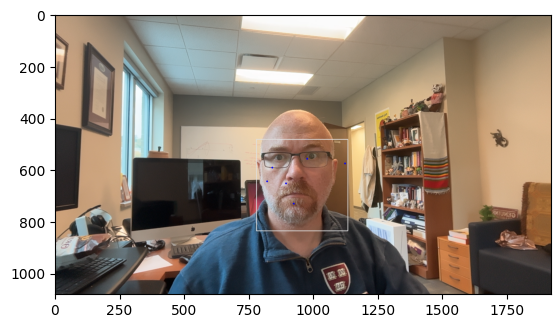

In [29]:
face_detection=mp_face_detection.FaceDetection(model_selection=0, min_detection_confidence=0.5)
results = face_detection.process(frame_rgb)

frame_rgb_face_det=frame_rgb.copy()
if results.detections:
    for detection in results.detections:
        mp_drawing.draw_detection(frame_rgb_face_det, detection)

plt.imshow(frame_rgb_face_det)

I0000 00:00:1762186238.140079 1570745 gl_context.cc:369] GL version: 2.1 (2.1 Metal - 90.5), renderer: Apple M4 Pro
W0000 00:00:1762186238.141357 1571316 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1762186238.146228 1571325 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


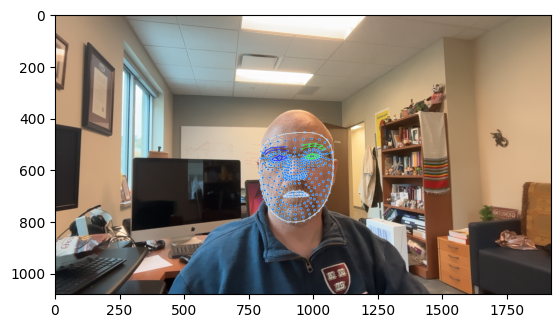

In [30]:
mp_face_mesh = mp.solutions.face_mesh

face_mesh=mp_face_mesh.FaceMesh(
    max_num_faces=1,
    refine_landmarks=True,
    min_detection_confidence=0.5,
    min_tracking_confidence=0.5) 

results = face_mesh.process(frame_rgb)

frame_rgb_face_landmarks=frame_rgb.copy()


# Check if landmarks were detected before attempting to draw
if results.multi_face_landmarks:
    for face_landmarks in results.multi_face_landmarks:
        mp_drawing.draw_landmarks(
                image=frame_rgb_face_landmarks,
                landmark_list=face_landmarks,
                connections=mp_face_mesh.FACEMESH_TESSELATION,
                landmark_drawing_spec=mp_drawing.DrawingSpec(thickness=2, color=(0, 120, 255)),
                connection_drawing_spec=mp_drawing_styles
                .get_default_face_mesh_tesselation_style())
        mp_drawing.draw_landmarks(
                image=frame_rgb_face_landmarks,
                landmark_list=face_landmarks,
                connections=mp_face_mesh.FACEMESH_CONTOURS,
                landmark_drawing_spec=None,
                connection_drawing_spec=mp_drawing_styles
                .get_default_face_mesh_contours_style())
        mp_drawing.draw_landmarks(
                image=frame_rgb_face_landmarks,
                landmark_list=face_landmarks,
                connections=mp_face_mesh.FACEMESH_IRISES,
                landmark_drawing_spec=None,
                connection_drawing_spec=mp_drawing_styles
                .get_default_face_mesh_iris_connections_style())

plt.imshow(frame_rgb_face_landmarks)

In [31]:
# From the documentation 
# https://storage.googleapis.com/mediapipe-assets/documentation/mediapipe_face_landmark_fullsize.png

# 10 - center of forehead
# 4  - tip of nose
# 103- right corner of forehead
# 332- left corner of forehead

landmarks=results.multi_face_landmarks[0]

In [32]:
def find_helmert_transform(src_points, dst_points):
    """
    Finds the 7-parameter Helmert (similarity) transformation between two
    sets of corresponding 3D points using a least-squares approach.
    """
    
    # Translate both sets of points to their centroids
    src_centroid = np.mean(src_points, axis=0)
    dst_centroid = np.mean(dst_points, axis=0)
    
    src_centered = src_points - src_centroid
    dst_centered = dst_points - dst_centroid
    
    # Compute the 3x3 covariance matrix H
    H = src_centered.T @ dst_centered
    
    # Compute the singular value decomposition (SVD) of H
    U, S, Vt = np.linalg.svd(H)
    
    # Compute the rotation matrix R
    R_matrix = Vt.T @ U.T
    
    # Handle reflection case
    if np.linalg.det(R_matrix) < 0:
        Vt[2, :] *= -1
        R_matrix = Vt.T @ U.T
    
  
    # Compute the scale factor (s)
    # The scale is the ratio of the norms of the centered point sets
    src_norm_sq = np.sum(src_centered**2)
    dst_norm_sq = np.sum(dst_centered**2)
    scale = np.sqrt(dst_norm_sq / src_norm_sq)
    R_matrix=R_matrix*scale
    
    # Compute the translation vector (T)
    # T = dst_centroid - s * R * src_centroid
    translation = dst_centroid - (R_matrix@src_centroid)
    translation=np.expand_dims(translation,axis=1)
   
    return R_matrix, translation

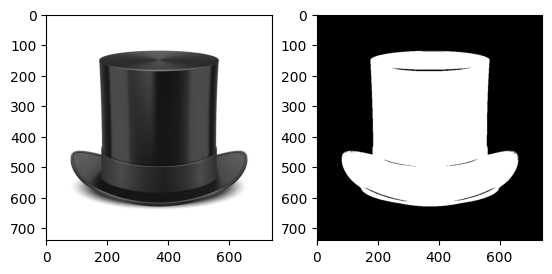

In [33]:
hat_image = cv2.imread(os.path.relpath('top-hat.jpg'))
hat_image=cv2.cvtColor(hat_image,cv2.COLOR_BGR2RGB)

_,hat_mask=cv2.threshold(cv2.cvtColor(hat_image,cv2.COLOR_RGB2GRAY),100,255,cv2.THRESH_BINARY_INV)

plt.subplot(121)
plt.imshow(hat_image)

plt.subplot(122)
plt.imshow(hat_mask,cmap='gray')

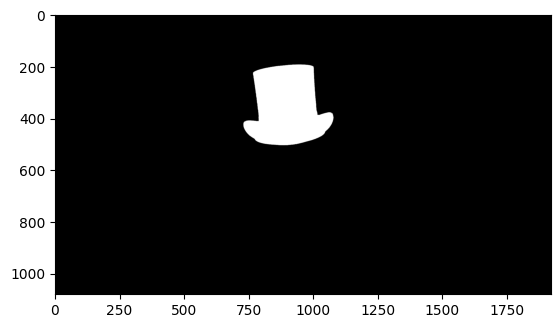

In [34]:
h,w=frame_rgb.shape[:2]

headpoints=np.array([
        [landmarks.landmark[10].x*w,landmarks.landmark[10].y*h],
        [landmarks.landmark[4].x*w,landmarks.landmark[4].y*h],
        [landmarks.landmark[103].x*w,landmarks.landmark[103].y*h],
        [landmarks.landmark[332].x*w,landmarks.landmark[332].y*h]])

hatpoints=np.array([[390,610],
                    [390,750],
                    [200,580],
                    [600,600]])

R,T=find_helmert_transform(hatpoints,headpoints)

rotation_matrix=np.hstack((R,T))

rotated_hat = cv2.warpAffine(hat_image, rotation_matrix, (w, h))
rotated_hat_mask = cv2.warpAffine(hat_mask, rotation_matrix, (w, h))

rotated_hat_mask = cv2.morphologyEx(rotated_hat_mask, cv2.MORPH_CLOSE,
                                     np.ones((5,5), np.uint8),iterations=2)

plt.imshow(rotated_hat_mask,cmap='gray')


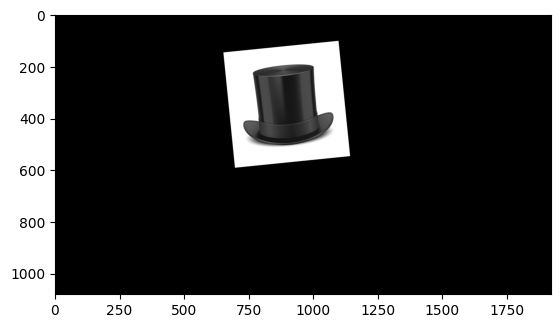

In [35]:
plt.imshow(rotated_hat)

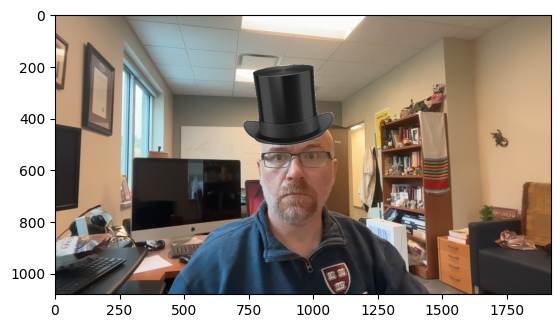

In [36]:
hat_masked = cv2.bitwise_and(rotated_hat, rotated_hat, mask=rotated_hat_mask)
frame_masked=cv2.bitwise_and(frame_rgb, frame_rgb, mask=cv2.bitwise_not(rotated_hat_mask))

frame_withhat=cv2.add(frame_masked,hat_masked)

plt.imshow(frame_withhat)

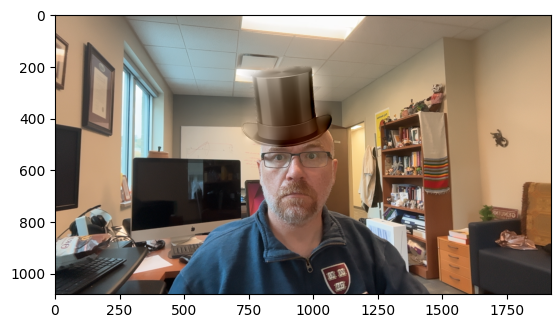

In [37]:
# Define the center of the cloning region in the destination image
M=cv2.moments(rotated_hat_mask)
cx = int(M["m10"] / M["m00"])
cy = int(M["m01"] / M["m00"])
center = (cx,cy)

# Perform seamless cloning
output = cv2.seamlessClone(rotated_hat,frame_rgb, cv2.dilate(rotated_hat_mask.copy(),kernel=np.ones((7,7), np.uint8)), center, cv2.NORMAL_CLONE)

plt.imshow(output)